# Лабораторная работа №1: «Метод обратного распространения ошибки»

**Выполнил:** Колесников Д.Е., группа ______

**Цель:** изучить метод обратного распространения ошибки (backpropagation) на примере двухслойной полносвязной сети
(один скрытый слой) и обучить её классифицировать рукописные цифры MNIST. Реализация — только на NumPy.

**Конфигурация сети**

| | |
|---|---|
| Входной слой | $N = w \times h = 28 \cdot 28 = 784$ нейрона, без активации |
| Скрытый слой | $K = 300$ нейронов (в задании — $s$), ReLU |
| Выходной слой | $M = 10$ нейронов (в задании — $k$), softmax |
| Функция ошибки | кросс-энтропия |
| Метод обучения | мини-пакетный SGD: `lr = 0.1`, `batch_size = 32`, `epochs = 20` |

## 1. Теория

### 1.0. Обозначения

Используется нотация лекции «Свёрточные нейронные сети» (раздел «Метод обратного распространения ошибки»).

| Обозначение | Смысл |
|---|---|
| $x^k,\ y^k$, $k = \overline{1, L}$ | $k$-й обучающий пример и его метка, $L = 60\,000$ |
| $x_i$, $i = \overline{1, N}$ | входы сети (пиксели), $N = w \cdot h = 28 \cdot 28 = 784$ |
| $v^{(1)}_j,\ s_j$, $j = \overline{1, K}$ | линейная активация и выход скрытого нейрона, $K = 300$ (в задании — $s$) |
| $v^{(2)}_m,\ u_m$, $m = \overline{1, M}$ | линейная активация и выход сети, $M = 10$ классов (в задании — $k$) |
| $w^{(1)}_{ij},\ b^{(1)}_j$ | вес связи «вход $i$ → скрытый нейрон $j$» и смещение скрытого нейрона |
| $w^{(2)}_{jm},\ b^{(2)}_m$ | вес связи «скрытый нейрон $j$ → выход $m$» и смещение выходного нейрона |
| $\varphi(v) = \max(0, v)$ | функция активации скрытого слоя (ReLU) |
| $y^k_m$ | $y^k_m = 1 \Leftrightarrow x^k$ принадлежит классу $m$, иначе $y^k_m = 0$ (one-hot) |
| $\delta^{(2)}_m,\ \delta^{(1)}_j$ | локальные градиенты: $\delta^{(2)}_m = \dfrac{\partial E}{\partial v^{(2)}_m}$, $\delta^{(1)}_j = \dfrac{\partial E}{\partial v^{(1)}_j}$ |
| $\eta$ | скорость обучения, $B$ — размер пачки |

### 1.1. Прямой проход

$$
v^{(1)}_j = \sum_{i=1}^{N} w^{(1)}_{ij}\, x_i + b^{(1)}_j, \qquad
s_j = \varphi\big(v^{(1)}_j\big), \qquad j = \overline{1, K}
$$

$$
v^{(2)}_m = \sum_{j=1}^{K} w^{(2)}_{jm}\, s_j + b^{(2)}_m, \qquad
u_m = \frac{e^{v^{(2)}_m}}{\sum_{l=1}^{M} e^{v^{(2)}_l}}, \qquad m = \overline{1, M}
$$

### 1.2. Задача обучения

В лекции для классификации записана кросс-энтропия $-\frac1L\sum_k\sum_m \big[y^k_m \ln u^k_m + (1 - y^k_m)\ln(1 - u^k_m)\big]$ —
это вариант для случая, когда объект может относиться **к нескольким классам** (каждый выход — независимая вероятность).
У нас каждая цифра принадлежит ровно одному классу, выходы связаны softmax ($\sum_m u_m = 1$), поэтому используется
категориальная кросс-энтропия — слагаемое с $(1 - y)$ отсутствует:

$$
\min_w E(w) = \min_w \left\{ -\frac{1}{L} \sum_{k=1}^{L} \sum_{m=1}^{M} y^k_m \ln u^k_m \right\}.
$$

Далее $E(w) = -\sum_{m=1}^{M} y_m \ln u_m$ — функция ошибки для одного примера (индекс $k$ опускаем).

### 1.3. Градиент на выходном слое (softmax + кросс-энтропия)

Производная softmax: $\dfrac{\partial u_l}{\partial v^{(2)}_m} = u_l\big([l = m] - u_m\big)$, где $[l = m]$ равно 1 при $l = m$ и 0 иначе. Тогда

$$
\delta^{(2)}_m = \frac{\partial E}{\partial v^{(2)}_m}
= -\sum_{l=1}^{M} \frac{y_l}{u_l} \cdot u_l\big([l = m] - u_m\big)
= -y_m + u_m \sum_{l=1}^{M} y_l
= \boxed{\,u_m - y_m\,}
$$

(так как $\sum_l y_l = 1$). Поэтому softmax и кросс-энтропию удобно рассматривать вместе: якобиан softmax ($M \times M$) явно не нужен.

### 1.4. Обратный проход

По правилу цепочки (как в лекции: $\frac{\partial E}{\partial w} = \frac{\partial E}{\partial v}\frac{\partial v}{\partial w}$) и так как
$\dfrac{\partial v^{(2)}_m}{\partial w^{(2)}_{jm}} = s_j$:

$$
\frac{\partial E}{\partial w^{(2)}_{jm}} = \delta^{(2)}_m\, s_j, \qquad
\frac{\partial E}{\partial b^{(2)}_m} = \delta^{(2)}_m .
$$

Ошибка передаётся на скрытый слой: $v^{(1)}_j$ влияет на $E$ через $s_j$ и все $v^{(2)}_m$, производная ReLU $\varphi'(v) = [v > 0]$:

$$
\delta^{(1)}_j = \frac{\partial E}{\partial s_j}\frac{\partial s_j}{\partial v^{(1)}_j}
= \varphi'\big(v^{(1)}_j\big) \sum_{m=1}^{M} \delta^{(2)}_m\, w^{(2)}_{jm},
$$

$$
\frac{\partial E}{\partial w^{(1)}_{ij}} = \delta^{(1)}_j\, x_i, \qquad
\frac{\partial E}{\partial b^{(1)}_j} = \delta^{(1)}_j .
$$

### 1.5. Коррекция весов (SGD по пачкам)

На каждом шаге берётся очередная пачка $\mathcal{B}$ из $B$ примеров (данные перемешиваются в начале каждой эпохи),
градиент усредняется по пачке, и каждый параметр $w$ (веса и смещения обоих слоёв) корректируется:

$$
w(t+1) = w(t) - \eta\, \frac{1}{B} \sum_{k \in \mathcal{B}} \frac{\partial E\big(x^k, y^k\big)}{\partial w},
\qquad \eta = 0.1 .
$$

### 1.6. Матричная форма (как в коде)

Пачка записывается по строкам: $X \in \mathbb{R}^{B \times N}$ (строка — $x^k$), $Y \in \{0,1\}^{B \times M}$;
$W^{(1)} = \big(w^{(1)}_{ij}\big) \in \mathbb{R}^{N \times K}$, $W^{(2)} = \big(w^{(2)}_{jm}\big) \in \mathbb{R}^{K \times M}$.
Суммы по $i$ и $j$ становятся матричными произведениями, а усреднение по пачке — множителем $1/B$:

| Формула | Код |
|---|---|
| $V^{(1)} = X W^{(1)} + b^{(1)}$, $\ S = \varphi(V^{(1)})$ | `V1 = X @ W1 + b1`, `S = relu(V1)` |
| $V^{(2)} = S\, W^{(2)} + b^{(2)}$, $\ U = \operatorname{softmax}(V^{(2)})$ | `V2 = S @ W2 + b2`, `softmax(V2)` |
| $\Delta^{(2)} = \frac{1}{B}(U - Y)$ | `delta2 = (softmax(V2) - Y) / B` |
| $\frac{\partial E}{\partial W^{(2)}} = S^\top \Delta^{(2)}$, $\ \frac{\partial E}{\partial b^{(2)}} = \sum_k \Delta^{(2)}_{k\cdot}$ | `S.T @ delta2`, `delta2.sum(axis=0)` |
| $\Delta^{(1)} = \big(\Delta^{(2)} W^{(2)\top}\big) \odot [V^{(1)} > 0]$ | `delta1 = (delta2 @ W2.T) * (V1 > 0)` |
| $\frac{\partial E}{\partial W^{(1)}} = X^\top \Delta^{(1)}$, $\ \frac{\partial E}{\partial b^{(1)}} = \sum_k \Delta^{(1)}_{k\cdot}$ | `X.T @ delta1`, `delta1.sum(axis=0)` |

Размерности сходятся: $X^\top\Delta^{(1)}$ — $(N\times B)(B\times K) = N\times K$, $S^\top\Delta^{(2)}$ — $(K\times B)(B\times M) = K\times M$.

### 1.7. Инициализация весов

«Неправильная» инициализация (например, $w \sim \mathcal{N}(0, 1)$ или $U[0,1)$) даёт огромные значения $v^{(1)}_j$
(дисперсия растёт как $N \cdot \mathbb{E}[x^2]\operatorname{Var}(w)$), softmax насыщается и обучение идёт хуже (см. эксперимент в разделе 7).

Используем:
- **He (Kaiming)** для слоя с ReLU: $w^{(1)}_{ij} \sim \mathcal{N}\!\left(0, \frac{2}{N}\right)$ — множитель 2 компенсирует то, что ReLU обнуляет половину входов, и дисперсия активаций сохраняется от слоя к слою;
- **Xavier (Glorot)** для выходного слоя: $w^{(2)}_{jm} \sim \mathcal{N}\!\left(0, \frac{2}{K + M}\right)$ — баланс дисперсий прямого и обратного прохода;
- смещения $b^{(1)}_j = 0$, $b^{(2)}_m = 0$.

### 1.8. Численная устойчивость

- $u_m = \dfrac{e^{v_m - c}}{\sum_l e^{v_l - c}}$ при $c = \max_l v_l$ — значение не меняется, но исключается переполнение $e^{v}$.
- $\ln u_m$ считаем как $v_m - c - \ln\sum_l e^{v_l - c}$ (log-sum-exp), без взятия логарифма от нуля.

## 2. Загрузка и предобработка данных

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
print("NumPy", np.__version__)

NumPy 2.5.3


MNIST хранится в формате IDX: заголовок (magic number, размерности, big-endian `int32`) и далее сырые байты.
Функция ищет файлы в папке `data/` (подходят и `.gz` из оригинального набора, и распакованные файлы с Kaggle
вида `train-images.idx3-ubyte`); если файлов нет — скачивает их с зеркала.

In [2]:
DATA_DIR = Path("data")
MIRRORS = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://raw.githubusercontent.com/fgnt/mnist/master/",
]
FILES = {
    "train_images": "train-images-idx3-ubyte",
    "train_labels": "train-labels-idx1-ubyte",
    "test_images": "t10k-images-idx3-ubyte",
    "test_labels": "t10k-labels-idx1-ubyte",
}


def find_or_download(stem):
    # Kaggle: 'train-images.idx3-ubyte', оригинал: 'train-images-idx3-ubyte(.gz)'
    kaggle_name = stem.replace("-idx", ".idx")
    for name in (stem, stem + ".gz", kaggle_name):
        for path in DATA_DIR.rglob(name):
            return path
    DATA_DIR.mkdir(exist_ok=True)
    target = DATA_DIR / (stem + ".gz")
    for base in MIRRORS:
        try:
            print("downloading", base + target.name)
            urllib.request.urlretrieve(base + target.name, target)
            return target
        except Exception as e:
            print("  failed:", e)
    raise FileNotFoundError(f"Не удалось найти или скачать {stem}")


def read_idx(path):
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, "rb") as f:
        zero, dtype_code, ndim = struct.unpack(">HBB", f.read(4))
        assert zero == 0 and dtype_code == 0x08, "ожидается IDX с типом uint8"
        shape = struct.unpack(">" + "I" * ndim, f.read(4 * ndim))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(shape)


raw = {key: read_idx(find_or_download(stem)) for key, stem in FILES.items()}
for key, arr in raw.items():
    print(f"{key:13s} shape={arr.shape} dtype={arr.dtype}")

train_images  shape=(60000, 28, 28) dtype=uint8
train_labels  shape=(60000,) dtype=uint8
test_images   shape=(10000, 28, 28) dtype=uint8
test_labels   shape=(10000,) dtype=uint8


**Предобработка:**
- изображение $28\times28$ разворачивается в вектор длины 784;
- яркость переводится из $[0, 255]$ в $[0, 1]$ (иначе $v^{(1)}_j$ были бы в 255 раз больше, и при `lr = 0.1` обучение разошлось бы);
- метки переводятся в one-hot векторы длины 10 (нужны для $\delta^{(2)}_m = u_m - y_m$).

Используем `float32`: точности хватает, а матричные умножения идут примерно вдвое быстрее, чем в `float64`.

In [3]:
def preprocess(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255.0


def one_hot(labels, k=10):
    Y = np.zeros((len(labels), k), dtype=np.float32)
    Y[np.arange(len(labels)), labels] = 1.0
    return Y


X_train, y_train = preprocess(raw["train_images"]), raw["train_labels"].astype(np.int64)
X_test, y_test = preprocess(raw["test_images"]), raw["test_labels"].astype(np.int64)
Y_train = one_hot(y_train)

print(f"Обучающая выборка: {len(X_train)} примеров")
print(f"Тестовая выборка:  {len(X_test)} примеров")
print(f"Форма одного изображения: {raw['train_images'].shape[1:]} -> вектор {X_train.shape[1:]}")
print(f"Форма меток: {y_train.shape} (номер класса), one-hot: {Y_train.shape}")
print(f"Диапазон пикселей после нормировки: [{X_train.min()}, {X_train.max()}]")
print("Число примеров по классам (train):", np.bincount(y_train))

Обучающая выборка: 60000 примеров
Тестовая выборка:  10000 примеров
Форма одного изображения: (28, 28) -> вектор (784,)
Форма меток: (60000,) (номер класса), one-hot: (60000, 10)


Диапазон пикселей после нормировки: [0.0, 1.0]
Число примеров по классам (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


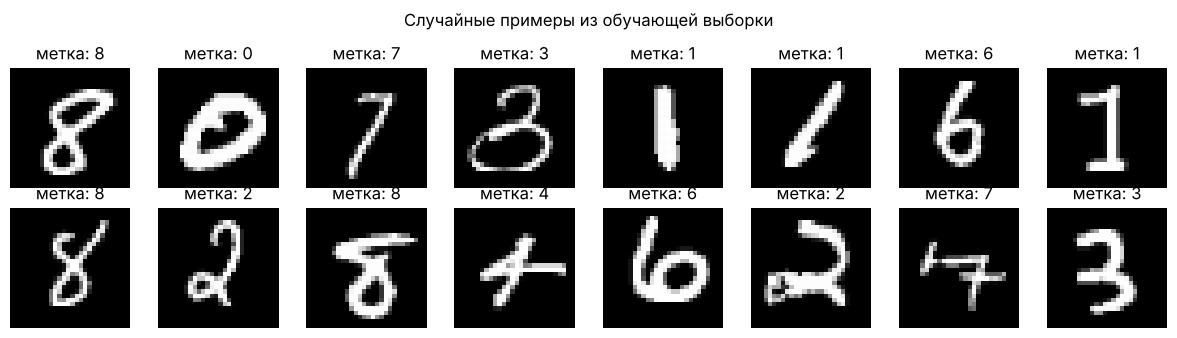

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
idx = rng.choice(len(X_train), size=axes.size, replace=False)
for ax, i in zip(axes.flat, idx):
    ax.imshow(raw["train_images"][i], cmap="gray")
    ax.set_title(f"метка: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Случайные примеры из обучающей выборки")
plt.tight_layout()
plt.show()

## 3. Реализация сети

In [5]:
def relu(z):
    return np.maximum(z, 0)


def softmax(V):
    V = V - V.max(axis=1, keepdims=True)          # численная устойчивость: вычитаем c = max_l v_l
    e = np.exp(V)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(V2, Y):
    # E, усреднённая по пачке, через log-sum-exp: ln u_m = v_m - c - ln sum_l exp(v_l - c)
    V = V2 - V2.max(axis=1, keepdims=True)
    log_u = V - np.log(np.exp(V).sum(axis=1, keepdims=True))
    return -np.mean(np.sum(Y * log_u, axis=1))


class TwoLayerNet:
    # N -> K (ReLU) -> M (softmax)

    def __init__(self, n_in, n_hidden, n_out, rng, dtype=np.float32):
        # He-инициализация для слоя с ReLU, Xavier — для выходного слоя
        self.W1 = (rng.standard_normal((n_in, n_hidden)) * np.sqrt(2.0 / n_in)).astype(dtype)
        self.b1 = np.zeros((1, n_hidden), dtype=dtype)
        self.W2 = (rng.standard_normal((n_hidden, n_out)) * np.sqrt(2.0 / (n_hidden + n_out))).astype(dtype)
        self.b2 = np.zeros((1, n_out), dtype=dtype)

    def forward(self, X):
        V1 = X @ self.W1 + self.b1         # v^(1): линейные активации скрытого слоя
        S = relu(V1)                       # s = phi(v^(1))
        V2 = S @ self.W2 + self.b2         # v^(2): линейные активации выходного слоя
        self.cache = (X, V1, S)            # сохраняем то, что нужно для обратного прохода
        return V2                          # softmax(V2) = u применяем там, где он нужен

    def backward(self, V2, Y):
        X, V1, S = self.cache
        B = X.shape[0]
        delta2 = (softmax(V2) - Y) / B             # delta^(2) = (u - y) / B
        dW2 = S.T @ delta2                         # dE/dw^(2)_jm = delta^(2)_m * s_j
        db2 = delta2.sum(axis=0, keepdims=True)
        delta1 = (delta2 @ self.W2.T) * (V1 > 0)   # delta^(1) = phi'(v^(1)) * sum_m delta^(2)_m w^(2)_jm
        dW1 = X.T @ delta1                         # dE/dw^(1)_ij = delta^(1)_j * x_i
        db1 = delta1.sum(axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, grads, lr):
        for name, g in grads.items():
            getattr(self, name)[...] -= lr * g     # обновление «на месте»

    def predict(self, X, batch=10000):
        return np.concatenate([np.argmax(self.forward(X[i:i + batch]), axis=1)
                               for i in range(0, len(X), batch)])

### 3.1. Проверка градиентов

Прежде чем обучать, убедимся, что аналитические формулы из п. 1.3–1.4 совпадают с численной производной
$\dfrac{\partial E}{\partial w} \approx \dfrac{E(w + \varepsilon) - E(w - \varepsilon)}{2\varepsilon}$
(центральная разность, ошибка $O(\varepsilon^2)$). Проверяем на маленькой сети в `float64` по случайным элементам каждого параметра.
Относительная ошибка порядка $10^{-7}$ и меньше означает, что градиенты посчитаны верно.

In [6]:
def gradient_check(n_checks=20, eps=1e-5):
    g_rng = np.random.default_rng(0)
    net = TwoLayerNet(784, 16, 10, g_rng, dtype=np.float64)
    Xb = X_train[:8].astype(np.float64)
    Yb = Y_train[:8].astype(np.float64)
    # ненулевые смещения, чтобы проверка db была содержательной
    net.b1 += g_rng.standard_normal(net.b1.shape) * 0.1
    net.b2 += g_rng.standard_normal(net.b2.shape) * 0.1

    grads = net.backward(net.forward(Xb), Yb)
    for name in ("W1", "b1", "W2", "b2"):
        param = getattr(net, name)
        errs = []
        for _ in range(n_checks):
            ij = tuple(g_rng.integers(0, d) for d in param.shape)
            old = param[ij]
            param[ij] = old + eps; lp = cross_entropy(net.forward(Xb), Yb)
            param[ij] = old - eps; lm = cross_entropy(net.forward(Xb), Yb)
            param[ij] = old
            num, ana = (lp - lm) / (2 * eps), grads[name][ij]
            errs.append(abs(num - ana) / max(1e-12, abs(num) + abs(ana)))
        print(f"{name}: max relative error = {max(errs):.2e}")


gradient_check()

W1: max relative error = 9.38e-11
b1: max relative error = 4.41e-09
W2: max relative error = 2.04e-08
b2: max relative error = 8.25e-09


## 4. Обучение на контрольных параметрах

In [7]:
def classification_error(net, X, y):
    return np.mean(net.predict(X) != y)


def train(net, X, Y, y, lr, batch_size, epochs, rng):
    history = {"loss": [], "train_err": [], "time": []}
    N = len(X)
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        perm = rng.permutation(N)          # перемешивание в начале каждой эпохи
        loss_sum = 0.0
        for start in range(0, N, batch_size):
            batch = perm[start:start + batch_size]
            Xb, Yb = X[batch], Y[batch]
            V2 = net.forward(Xb)
            loss_sum += cross_entropy(V2, Yb) * len(batch)
            net.step(net.backward(V2, Yb), lr)
        epoch_time = time.perf_counter() - t0

        train_err = classification_error(net, X, y)   # ошибка на всей обучающей выборке после эпохи
        history["loss"].append(loss_sum / N)
        history["train_err"].append(train_err)
        history["time"].append(epoch_time)
        print(f"Эпоха {epoch:2d}/{epochs}: loss = {loss_sum / N:.4f}, "
              f"ошибка на train = {train_err:.4f} (точность {1 - train_err:.2%}), "
              f"время эпохи = {epoch_time:.2f} с")
    return history

In [8]:
LEARNING_RATE = 0.1
BATCH_SIZE = 32
HIDDEN = 300
EPOCHS = 20

net = TwoLayerNet(784, HIDDEN, 10, rng)
t_start = time.perf_counter()
history = train(net, X_train, Y_train, y_train, LEARNING_RATE, BATCH_SIZE, EPOCHS, rng)
print(f"\nСуммарное время обучения: {time.perf_counter() - t_start:.1f} с")

Эпоха  1/20: loss = 0.2843, ошибка на train = 0.0418 (точность 95.82%), время эпохи = 1.54 с


Эпоха  2/20: loss = 0.1341, ошибка на train = 0.0268 (точность 97.32%), время эпохи = 1.59 с


Эпоха  3/20: loss = 0.0936, ошибка на train = 0.0187 (точность 98.13%), время эпохи = 1.39 с


Эпоха  4/20: loss = 0.0714, ошибка на train = 0.0156 (точность 98.44%), время эпохи = 1.74 с


Эпоха  5/20: loss = 0.0576, ошибка на train = 0.0113 (точность 98.87%), время эпохи = 1.93 с


Эпоха  6/20: loss = 0.0467, ошибка на train = 0.0094 (точность 99.06%), время эпохи = 1.61 с


... (10 outputs left out)

Эпоха 17/20: loss = 0.0078, ошибка на train = 0.0003 (точность 99.97%), время эпохи = 1.57 с


Эпоха 18/20: loss = 0.0068, ошибка на train = 0.0003 (точность 99.97%), время эпохи = 1.76 с


Эпоха 19/20: loss = 0.0060, ошибка на train = 0.0002 (точность 99.98%), время эпохи = 1.64 с


Эпоха 20/20: loss = 0.0054, ошибка на train = 0.0001 (точность 99.99%), время эпохи = 1.99 с

Суммарное время обучения: 39.0 с


## 5. Результат на тестовой выборке

In [9]:
test_pred = net.predict(X_test)
test_err = np.mean(test_pred != y_test)
print(f"Ошибка классификации на тестовой выборке: {test_err:.4f}")
print(f"Точность на тестовой выборке: {1 - test_err:.2%}")

Ошибка классификации на тестовой выборке: 0.0174
Точность на тестовой выборке: 98.26%


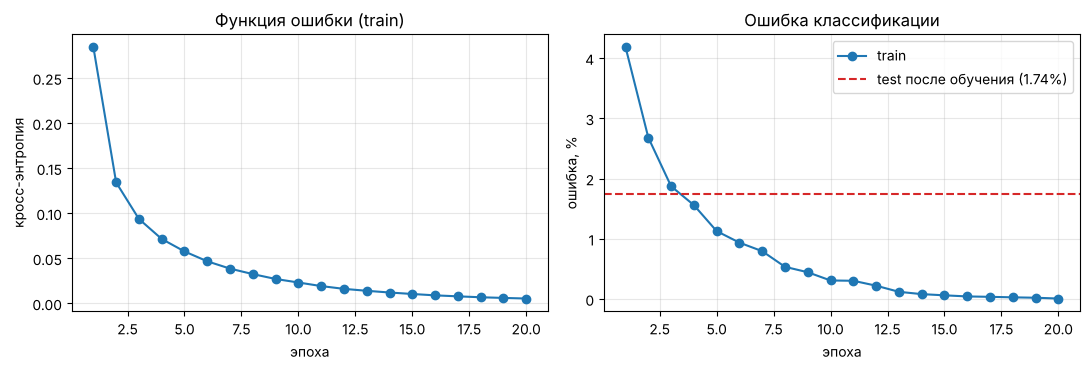

In [10]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(epochs_axis, history["loss"], marker="o")
ax1.set_xlabel("эпоха"); ax1.set_ylabel("кросс-энтропия"); ax1.set_title("Функция ошибки (train)")
ax1.grid(alpha=0.3)
ax2.plot(epochs_axis, np.array(history["train_err"]) * 100, marker="o", label="train")
ax2.axhline(test_err * 100, color="C3", linestyle="--", label=f"test после обучения ({test_err:.2%})")
ax2.set_xlabel("эпоха"); ax2.set_ylabel("ошибка, %"); ax2.set_title("Ошибка классификации")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

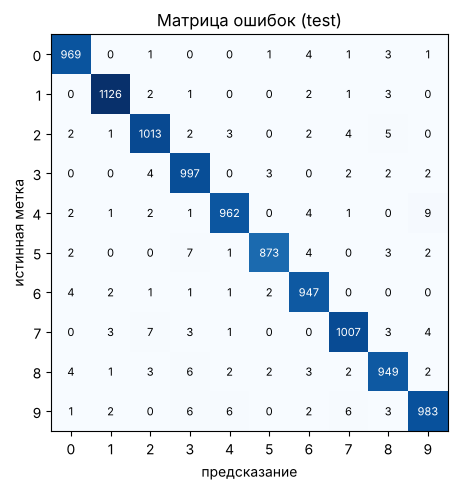

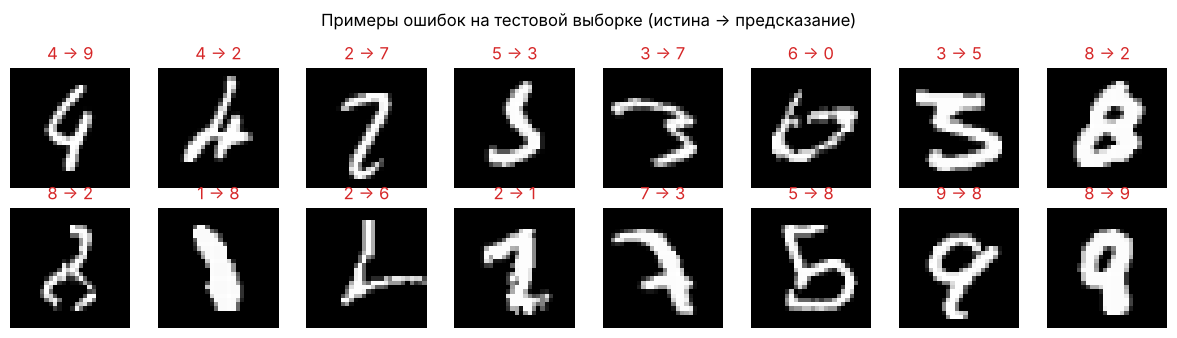

In [11]:
# матрица ошибок: строки — истинный класс, столбцы — предсказанный
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_test, test_pred), 1)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("предсказание"); ax.set_ylabel("истинная метка"); ax.set_title("Матрица ошибок (test)")
plt.tight_layout()
plt.show()

wrong = np.flatnonzero(test_pred != y_test)[:16]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(raw["test_images"][i], cmap="gray")
    ax.set_title(f"{y_test[i]} → {test_pred[i]}", color="C3")
    ax.axis("off")
plt.suptitle("Примеры ошибок на тестовой выборке (истина → предсказание)")
plt.tight_layout()
plt.show()

## 6. Что выучил скрытый слой

Веса $w^{(1)}_{ij}$, $i = \overline{1, N}$, одного скрытого нейрона $j$ (столбец матрицы $W^{(1)}$) — это 784 числа, по одному на пиксель, т.е. «шаблон» $28\times28$, с которым нейрон сравнивает
изображение (скалярное произведение). Красное — пиксели, которые возбуждают нейрон, синее — подавляют.
В центре видны штрихи и фрагменты контуров цифр. Мелкий «шум» по краям — это нетронутая случайная инициализация:
у MNIST на краях пиксели всегда нулевые, градиент $\partial E / \partial w^{(1)}_{ij} = \delta^{(1)}_j x_i$ по этим весам равен нулю, и они не обучаются.

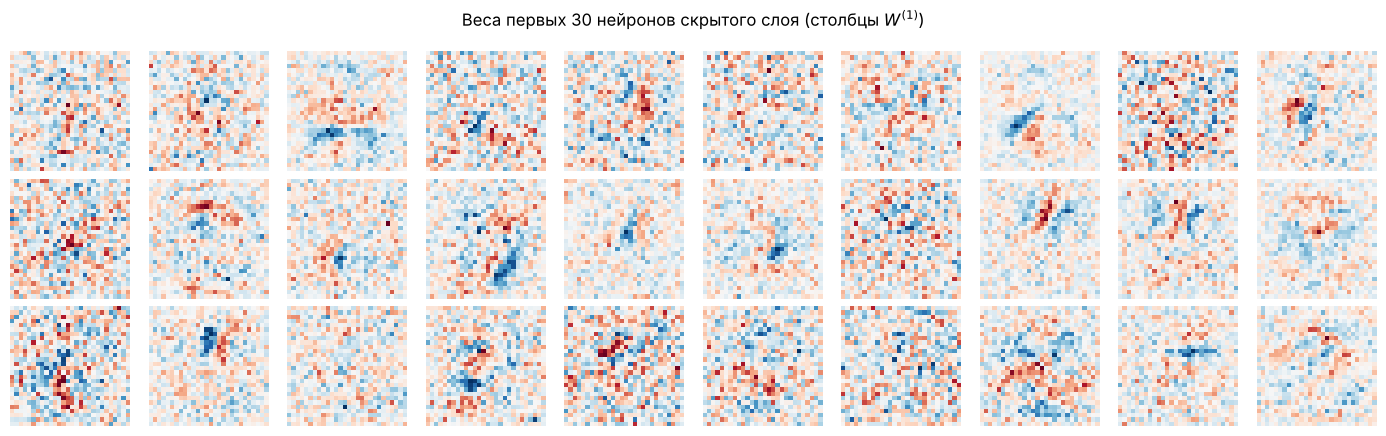

In [12]:
fig, axes = plt.subplots(3, 10, figsize=(14, 4.4))
for j, ax in enumerate(axes.flat):
    w = net.W1[:, j].reshape(28, 28)
    lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.axis("off")
plt.suptitle("Веса первых 30 нейронов скрытого слоя (столбцы $W^{(1)}$)")
plt.tight_layout()
plt.show()

## 7. Эксперимент: влияние инициализации весов

В подсказке к работе сказано, что с «неправильной» инициализацией получается ~95%. Проверим: обучим ту же сеть с теми же
контрольными параметрами, меняя только начальные веса (смещения везде нулевые):

| Вариант | $w^{(1)}_{ij}$ | $w^{(2)}_{jm}$ |
|---|---|---|
| He / Xavier (основной) | $\mathcal{N}(0, 2/N)$ | $\mathcal{N}(0, 2/(K+M))$ |
| стандартное нормальное | $\mathcal{N}(0, 1)$ | $\mathcal{N}(0, 1)$ |
| равномерное $[0, 1)$ | $U[0, 1)$ | $U[0, 1)$ |
| маленькие | $\mathcal{N}(0, 10^{-4})$ | $\mathcal{N}(0, 10^{-4})$ |

Для каждого варианта выводятся начальная ошибка (до обучения; «идеальная» для 10 классов $\ln 10 \approx 2.30$),
доля «мёртвых» ReLU-нейронов после обучения (ни разу не активировались на 10 000 обучающих примеров — их градиент всегда нулевой)
и точность на тесте. Эксперимент занимает ~1.5 минуты; на сдаче его можно пропустить, поставив `RUN_INIT_EXPERIMENT = False`.

In [13]:
RUN_INIT_EXPERIMENT = True

INITS = {
    "N(0, 1)":    lambda r, shape: r.standard_normal(shape),
    "U[0, 1)":    lambda r, shape: r.random(shape),
    "N(0, 1e-4)": lambda r, shape: r.standard_normal(shape) * 0.01,
}


def dead_fraction(net, X):
    net.forward(X)
    _, V1, _ = net.cache
    return np.mean((V1 > 0).sum(axis=0) == 0)


init_results = {"He / Xavier": dict(init_loss=None, dead=dead_fraction(net, X_train[:10000]),
                                    test_acc=1 - test_err, curve=history["train_err"])}
he_check = TwoLayerNet(784, HIDDEN, 10, np.random.default_rng(SEED))
init_results["He / Xavier"]["init_loss"] = cross_entropy(he_check.forward(X_train[:10000]), Y_train[:10000])

if RUN_INIT_EXPERIMENT:
    for name, init in INITS.items():
        r = np.random.default_rng(SEED)
        exp_net = TwoLayerNet(784, HIDDEN, 10, r)
        exp_net.W1[...] = init(r, exp_net.W1.shape)
        exp_net.W2[...] = init(r, exp_net.W2.shape)
        init_loss = cross_entropy(exp_net.forward(X_train[:10000]), Y_train[:10000])
        print(f"=== {name}: начальная ошибка {init_loss:.1f}")
        h = train(exp_net, X_train, Y_train, y_train, LEARNING_RATE, BATCH_SIZE, EPOCHS, np.random.default_rng(SEED))
        init_results[name] = dict(init_loss=init_loss, dead=dead_fraction(exp_net, X_train[:10000]),
                                  test_acc=np.mean(exp_net.predict(X_test) == y_test), curve=h["train_err"])
        print()

print(f"{'инициализация':14s} | {'нач. ошибка':>11s} | {'мёртвых ReLU':>12s} | {'точность (test)':>15s}")
for name, r in init_results.items():
    print(f"{name:14s} | {r['init_loss']:11.2f} | {r['dead']:12.1%} | {r['test_acc']:15.2%}")

=== N(0, 1): начальная ошибка 213.1


Эпоха  1/20: loss = 4.1127, ошибка на train = 0.0693 (точность 93.07%), время эпохи = 3.40 с


Эпоха  2/20: loss = 0.8156, ошибка на train = 0.0531 (точность 94.69%), время эпохи = 2.66 с


Эпоха  3/20: loss = 0.4748, ошибка на train = 0.0425 (точность 95.75%), время эпохи = 2.28 с


Эпоха  4/20: loss = 0.3167, ошибка на train = 0.0353 (точность 96.47%), время эпохи = 2.41 с


Эпоха  5/20: loss = 0.2330, ошибка на train = 0.0288 (точность 97.12%), время эпохи = 2.44 с


... (51 outputs left out)

Эпоха 17/20: loss = 0.0104, ошибка на train = 0.0007 (точность 99.93%), время эпохи = 1.43 с


Эпоха 18/20: loss = 0.0091, ошибка на train = 0.0008 (точность 99.91%), время эпохи = 1.52 с


Эпоха 19/20: loss = 0.0081, ошибка на train = 0.0010 (точность 99.90%), время эпохи = 1.49 с


Эпоха 20/20: loss = 0.0072, ошибка на train = 0.0006 (точность 99.94%), время эпохи = 1.52 с

инициализация  | нач. ошибка | мёртвых ReLU | точность (test)
He / Xavier    |        2.40 |         0.0% |          98.26%
N(0, 1)        |      213.07 |         0.0% |          95.39%
U[0, 1)        |      283.61 |        65.7% |          81.41%
N(0, 1e-4)     |        2.30 |         0.0% |          98.33%


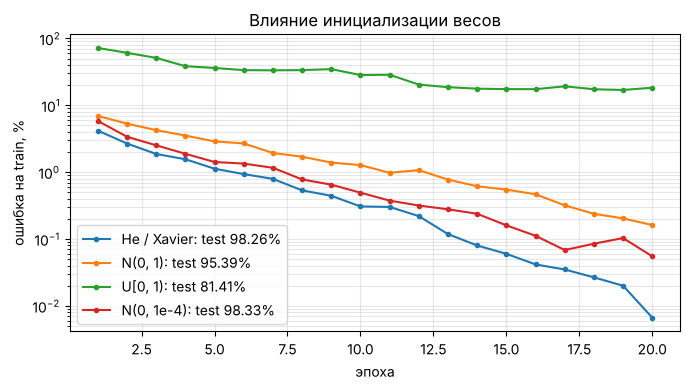

In [14]:
plt.figure(figsize=(7, 4))
for name, r in init_results.items():
    plt.plot(epochs_axis, np.array(r["curve"]) * 100, marker="o", ms=3, label=f"{name}: test {r['test_acc']:.2%}")
plt.yscale("log"); plt.xlabel("эпоха"); plt.ylabel("ошибка на train, %")
plt.title("Влияние инициализации весов"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

**Что показывает эксперимент.**

- **$\\mathcal{N}(0,1)$ — ~95%, как и сказано в подсказке.** Средний квадрат пикселя MNIST $\\mathbb{E}[x^2] \\approx 0.1$, поэтому
  дисперсия $v^{(1)}_j$ порядка $N \\cdot 0.1 \\approx 78$, а логиты — порядка сотен: начальная ошибка ~200 вместо $\\ln 10 \\approx 2.3$, softmax насыщен.
  Мёртвых нейронов при этом нет, и обучающую выборку сеть выучивает почти идеально (~99.8%), но **обобщает хуже**:
  шаги SGD малы по сравнению с весами масштаба 1, и в $W^{(1)}$ остаётся большая случайная составляющая — признаки скрытого слоя
  во многом случайные проекции, к которым выходной слой «подгоняется». Разрыв train/test — около 4.5% против ~1.7% у He.
- **$U[0,1)$ — хуже всего.** Все веса положительны, поэтому все нейроны видят почти одно и то же (сумму яркостей) и сильно
  скоррелированы; огромные начальные градиенты выталкивают значительную часть нейронов в $v^{(1)}_j < 0$ — это «мёртвые» ReLU
  (доля приведена в таблице), они больше не обучаются, и эффективная ширина скрытого слоя падает.
- **Маленькие веса $\\mathcal{N}(0, 10^{-4})$ работают не хуже He.** Для сети с одним скрытым слоем это ожидаемо:
  симметрия нарушена случайностью, начальная ошибка ровно $\\ln 10$, а градиент по $w^{(2)}_{jm} $ не мал ($\delta^{(2)}_m s_j$), так что $w^{(2)}$ быстро растут и
  «включают» градиент $\delta^{(1)}_j \propto \sum_m \delta^{(2)}_m w^{(2)}_{jm}$ для $w^{(1)}$. Проблема маленькой инициализации — затухание сигнала, оно проявляется в **глубоких** сетях,
  где множитель $<1$ накапливается через много слоёв. (Нулевая инициализация не сработала бы: все нейроны скрытого слоя
  получали бы одинаковый градиент и оставались бы одинаковыми.)
- **He / Xavier** подбирают масштаб так, чтобы дисперсия активаций сохранялась от слоя к слою; это правильный выбор
  независимо от глубины.

## 8. Сравнение с PyTorch

По заданию точность должна быть сравнима с результатом стандартного фреймворка. Для **сравнения** (не как часть решения)
обучим в PyTorch ту же архитектуру 784–300–10 с теми же контрольными параметрами: SGD без момента, `lr = 0.1`,
`batch_size = 32`, 20 эпох, кросс-энтропия. Инициализация — стандартная для `nn.Linear` (Kaiming uniform).
Если PyTorch не установлен, ячейка пропускается.

In [15]:
RUN_TORCH_COMPARISON = True

torch_acc = None
if RUN_TORCH_COMPARISON:
    try:
        import torch
        import torch.nn as nn
    except ImportError:
        print("PyTorch не установлен — сравнение пропущено")
    else:
        torch.manual_seed(SEED)
        torch.set_num_threads(max(1, torch.get_num_threads()))
        model = nn.Sequential(nn.Linear(784, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 10))
        opt = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
        loss_fn = nn.CrossEntropyLoss()        # softmax + кросс-энтропия
        Xt, yt = torch.from_numpy(X_train), torch.from_numpy(y_train)
        t_start = time.perf_counter()
        for epoch in range(1, EPOCHS + 1):
            t0 = time.perf_counter()
            for batch in torch.randperm(len(Xt)).split(BATCH_SIZE):
                loss = loss_fn(model(Xt[batch]), yt[batch])
                opt.zero_grad()
                loss.backward()
                opt.step()
            with torch.no_grad():
                tr_err = (model(Xt).argmax(1) != yt).float().mean().item()
            print(f"[PyTorch] эпоха {epoch:2d}/{EPOCHS}: ошибка на train = {tr_err:.4f}, "
                  f"время эпохи = {time.perf_counter() - t0:.2f} с")
        with torch.no_grad():
            torch_acc = (model(torch.from_numpy(X_test)).argmax(1).numpy() == y_test).mean()
        print(f"\nОбщее время PyTorch: {time.perf_counter() - t_start:.1f} с")

print(f"\nТочность на тесте — наша реализация (NumPy): {1 - test_err:.2%}")
if torch_acc is not None:
    print(f"Точность на тесте — PyTorch:               {torch_acc:.2%}")

[PyTorch] эпоха  1/20: ошибка на train = 0.0519, время эпохи = 2.09 с


[PyTorch] эпоха  2/20: ошибка на train = 0.0317, время эпохи = 1.99 с


[PyTorch] эпоха  3/20: ошибка на train = 0.0227, время эпохи = 1.84 с


[PyTorch] эпоха  4/20: ошибка на train = 0.0191, время эпохи = 2.22 с


[PyTorch] эпоха  5/20: ошибка на train = 0.0136, время эпохи = 1.83 с


[PyTorch] эпоха  6/20: ошибка на train = 0.0113, время эпохи = 1.91 с


... (10 outputs left out)

[PyTorch] эпоха 17/20: ошибка на train = 0.0007, время эпохи = 1.83 с


[PyTorch] эпоха 18/20: ошибка на train = 0.0004, время эпохи = 1.89 с


[PyTorch] эпоха 19/20: ошибка на train = 0.0003, время эпохи = 1.92 с


[PyTorch] эпоха 20/20: ошибка на train = 0.0002, время эпохи = 1.91 с

Общее время PyTorch: 38.4 с

Точность на тесте — наша реализация (NumPy): 98.26%
Точность на тесте — PyTorch:               98.18%


## 9. Выводы

1. Выведены формулы прямого и обратного прохода для сети 784–300(ReLU)–10(softmax) с кросс-энтропией.
   Ключевое упрощение: локальный градиент выходного слоя $\delta^{(2)}_m = u_m - y_m$.
2. Корректность аналитических градиентов подтверждена численной проверкой (центральные разности).
3. Сеть реализована на NumPy без фреймворков глубокого обучения и обучена мини-пакетным SGD
   на контрольных параметрах (`lr = 0.1`, `batch_size = 32`, `s = 300`, 20 эпох).
4. Точность на тестовой выборке около 98% и совпадает (в пределах нескольких десятых процента) с результатом той же
   архитектуры, обученной в PyTorch с теми же параметрами (раздел 8).
5. Эксперимент с инициализацией (раздел 7) подтверждает подсказку: при $\mathcal{N}(0,1)$ точность около 95%,
   причём обучающую выборку сеть выучивает, а страдает обобщение; при $U[0,1)$ — ещё хуже из-за «мёртвых» ReLU.
   Маленькие веса для неглубокой сети работают так же хорошо, как He/Xavier.
6. Ошибка на обучающей выборке в конце обучения близка к нулю, а на тестовой — порядка 2%:
   небольшое переобучение, которое можно уменьшить регуляризацией (L2, dropout) или ранней остановкой.